# NORMAL 开仓至 REBALANCE 配对

## tl;dr
最近 12 个已记录市场中有 13 轮实际开仓，全部配对。平均 53.153 秒、中位数 26.810 秒；开仓 OBI 强度与耗时 Pearson 0.210、Spearman 0.132，未见明确单调关系。

## Context & Methods
范围为北京时间 2026-10-17 22:45–23:45，早于新资金准入规则。主口径为本地首次观察到开仓 MATCHED 至对侧覆盖全部数量的最后 MATCHED。

### Key Assumptions
官方撮合时间不可用；信号取发单时最终 OBI。按去重经济成交 FIFO 分配补仓，部分成交须累计到开仓实际数量。无成交市场不计零耗时。样本是已成交开仓，不能推断全市场信号预测能力。

## Data
本目录 analyze.py 读取已冻结的 analysis.json，并逐个复验原始 journal 的 SHA-256、成交身份、数量和价格；再次检查这是最新 12 个已记录市场。无交易 API 调用。下方代码仅依赖标准库。

In [1]:
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src/polymaker').is_dir())
REVIEW = ROOT / 'docs/development/reviews/20261017_2245_2345_pairing'
"""Read-only NORMAL -> REBALANCE timing and signal analysis, standard library."""
import csv
import hashlib
import json
import math
import random
import statistics
from collections import defaultdict
from decimal import Decimal
from pathlib import Path

OUT = REVIEW
ROOT = OUT.parents[3]
BASE = OUT.parent / '20261017_2245_2345'
D = lambda x: Decimal(str(x))


def quant(v):
    v = sorted(v)
    return dict(n=len(v), mean=statistics.mean(v), median=statistics.median(v),
                p90=v[math.ceil(len(v)*.9)-1], p95=v[math.ceil(len(v)*.95)-1],
                min=v[0], max=v[-1]) if v else dict(n=0)


def ranks(v):
    ordered = sorted(v)
    return [(ordered.index(x)+1+len(ordered)-list(reversed(ordered)).index(x))/2 for x in v]


def correlation(x, y):
    return dict(pearson=statistics.correlation(x, y),
                spearman=statistics.correlation(ranks(x), ranks(y)), n=len(x))


def main():
    data = json.loads((BASE/'analysis.json').read_text())
    # Verify that this frozen cohort is still the newest twelve logged markets.
    catalog = []
    for p in (ROOT/'journal').glob('rdp_sm_*.jsonl'):
        try:
            with p.open() as f:
                head = json.loads(next(f))
            if head['kind']=='sm_session':
                slug=head['data']['payload']['slug']
                if slug.startswith('btc-updown-5m-'):
                    catalog.append(int(slug.rsplit('-',1)[1]))
        except (ValueError,KeyError,StopIteration):
            continue
    assert sorted(set(catalog))[-12:] == [m['epoch'] for m in data['markets']]
    cycles, residuals, sources = [], [], []
    assigned = defaultdict(Decimal)
    for m in data['markets']:
        p = Path(m['source'])
        raw = p.read_bytes()
        digest = hashlib.sha256(raw).hexdigest()
        expected=next(s for s in data['provenance'] if s['path']==m['source'])
        assert digest==expected['sha256']
        sources.append(dict(path=str(p), sha256=digest, bytes=len(raw)))
        records = [(i,json.loads(l)) for i,l in enumerate(raw.decode().splitlines(),1)]
        by = defaultdict(list)
        for line,r in records:
            by[r['kind']].append((line,r))
        decisions = {r['data']['payload']['intent']['window_id']:(line,r['data']['payload']['intent'])
                     for line,r in by['sm_obi_final_decision']}
        confirmed = {}
        for line,r in by['sm_trade']:
            q=r['data']['payload']
            if q['status']=='CONFIRMED':
                key=q['trade_id'],q['maker_order_id']
                if key in confirmed:assert confirmed[key][1]==q
                confirmed[key]=(line,q)
        fills=[f for f in data['fills'] if f['session_id']==m['session_id']]
        assert set(confirmed)=={(f['trade_id'],f['order_id']) for f in fills}
        for f in fills:
            _,q=confirmed[f['trade_id'],f['order_id']]
            assert D(q['size'])==D(f['quantity']) and D(q['price'])==D(f['price'])
        windows=[w for w in data['windows'] if w['session_id']==m['session_id']]
        opening_windows=[w for w in windows if w['phase']=='NORMAL' and w['fill_quantity']>0]
        offset=statistics.median(r['data']['payload']['completed_wall']-r['data']['payload']['completed_monotonic']
                                for _,r in by['sm_network_request'])
        for index,w in enumerate(opening_windows):
            next_post=opening_windows[index+1]['post_epoch'] if index+1<len(opening_windows) else float('inf')
            opening=sorted([f for f in fills if f['order_id']==w['order_id']], key=lambda f:f['matched_observed_epoch'])
            line,intent=decisions[w['session_id']+':'+w['window']]
            signal=intent.get('final_signal') or intent['signal']
            assert signal['label']=='VALID_'+w['side']
            assert D(signal['imbalance'])==D(w['obi'])
            signal_wall=float(signal['event_mono'])+offset
            assert 0 <= w['post_epoch']-signal_wall < .101
            repairs=[r for r in windows if r['phase']=='REBALANCE' and r['side']!=w['side']
                     and w['post_epoch']<r['post_epoch']<next_post]
            repair_ids={r['order_id'] for r in repairs}
            candidates=sorted([f for f in fills if f['order_id'] in repair_ids],
                              key=lambda f:(f['matched_observed_epoch'],f['confirmed_epoch'],f['trade_id']))
            remaining=sum((D(f['quantity']) for f in opening),D(0))
            entry_quantity=remaining
            allocated=[]
            for f in candidates:
                qty=min(remaining,D(f['quantity']))
                if qty>0:
                    allocated.append((f,qty))
                    assigned[f['trade_id'],f['order_id']]+=qty
                    remaining-=qty
            matched_start=min(f['matched_observed_epoch'] for f in opening)
            confirmed_start=max(f['confirmed_epoch'] for f in opening)
            complete=remaining==0
            matched_end=max(f['matched_observed_epoch'] for f,q in allocated) if complete else None
            confirmed_end=max(f['confirmed_epoch'] for f,q in allocated) if complete else None
            first_repair=next((r for r in repairs if r['submitted']),None)
            cost=sum((D(f['price'])*D(f['quantity']) for f in opening),D(0))
            repair_cost=sum((D(f['price'])*q for f,q in allocated),D(0))
            cycle=dict(market=m['market'],session_id=m['session_id'],window=w['window'],side=w['side'],
                entry_signal=float(signal['imbalance']),signal_strength=abs(float(signal['imbalance'])),
                entry_price=w['price'],entry_quantity=float(entry_quantity),entry_post=w['post_time'],
                opening_first_matched=min(f['matched_observed_time'] for f in opening),
                opening_last_confirmed=max(f['confirmed_observed_time'] for f in opening),
                pair_last_matched=max(f['matched_observed_time'] for f,q in allocated) if complete else None,
                pair_last_confirmed=max(f['confirmed_observed_time'] for f,q in allocated) if complete else None,
                complete=complete,unpaired_normal_quantity=float(remaining),
                matched_to_matched_s=matched_end-matched_start if complete else None,
                confirmed_to_confirmed_s=confirmed_end-confirmed_start if complete else None,
                signal_to_pair_confirmed_s=confirmed_end-signal_wall if complete else None,
                post_to_pair_confirmed_s=confirmed_end-w['post_epoch'] if complete else None,
                entry_confirmation_wait_s=confirmed_start-matched_start,
                confirmed_to_first_repair_post_s=first_repair['post_epoch']-confirmed_start if first_repair else None,
                first_repair_post_to_pair_match_s=matched_end-first_repair['post_epoch'] if complete and first_repair else None,
                repair_submissions=sum(r['submitted'] for r in repairs),
                repair_windows=len(repairs),stale_close_submissions=sum(r['submitted'] and r['close_reason']=='WS_BOOK_STALE' for r in repairs),
                normal_close_reason=w['close_reason'],normal_post_to_close_s=w['post_to_close_s'],
                fifo_acquisition_pair_gross=float(entry_quantity-cost-repair_cost) if complete else None,
                capital_constrained=(m['market']=='23:25' and w['window']=='w7'),
                source=m['source'],decision_source_line=line,
                opening_fill_lines=[f['source_line'] for f in opening],
                allocated_repair_fills=[dict(trade_id=f['trade_id'],order_id=f['order_id'],
                    quantity=float(q),price=f['price'],source_line=f['source_line']) for f,q in allocated])
            if complete:
                assert abs(cycle['matched_to_matched_s']-sum(cycle[k] for k in (
                    'entry_confirmation_wait_s','confirmed_to_first_repair_post_s','first_repair_post_to_pair_match_s')))<1e-6
            cycles.append(cycle)
        for f in fills:
            if any(w['order_id']==f['order_id'] and w['phase']=='REBALANCE' for w in windows):
                qty=D(f['quantity'])-assigned[f['trade_id'],f['order_id']]
                assert qty>=0
                if qty:residuals.append(dict(market=m['market'],side=f['side'],quantity=float(qty),price=f['price']))
    done=[c for c in cycles if c['complete']]
    assert len(cycles)==13 and len(done)==13
    assert sum(c['repair_submissions'] for c in cycles)==data['totals']['phases']['REBALANCE']
    assert abs(sum(r['quantity'] for r in residuals)-.02)<1e-9
    metric_names=['matched_to_matched_s','confirmed_to_confirmed_s','signal_to_pair_confirmed_s','post_to_pair_confirmed_s',
                  'entry_confirmation_wait_s','confirmed_to_first_repair_post_s','first_repair_post_to_pair_match_s','repair_submissions']
    def summarize(cs):
        return dict(metrics={k:quant([c[k] for c in cs]) for k in metric_names},
            signal_vs_duration=correlation([c['signal_strength'] for c in cs],[c['matched_to_matched_s'] for c in cs]),
            signal_vs_pair_gross=correlation([c['signal_strength'] for c in cs],[c['fifo_acquisition_pair_gross'] for c in cs]))
    bins=[]
    for lo,hi in [(.3,.6),(.6,.8),(.8,1.0000001)]:
        cs=[c for c in done if lo<=c['signal_strength']<hi]
        bins.append(dict(lower=lo,upper=min(hi,1),n=len(cs),duration=quant([c['matched_to_matched_s'] for c in cs])))
    # Bootstrap markets rather than individual cycles, retaining within-market clustering.
    rng=random.Random(20261018)
    groups=defaultdict(list)
    for c in done:groups[c['market']].append(c)
    names=list(groups)
    samples=[]
    for _ in range(20000):
        bs=[c for market in rng.choices(names,k=len(names)) for c in groups[market]]
        if len(set(c['signal_strength'] for c in bs))>1:
            samples.append(statistics.correlation([c['signal_strength'] for c in bs],[c['matched_to_matched_s'] for c in bs]))
    samples.sort()
    result=dict(scope='2026-10-17 22:45–23:45 Asia/Shanghai; latest 12 logged markets; before new NORMAL capital rule',
        definitions=dict(unit='one filled NORMAL order and subsequent opposite REBALANCE fills; FIFO allocation up to entry quantity',
            primary='first local MATCHED observation of opening -> last local MATCHED observation needed to cover all opening shares',
            confirmed='last opening CONFIRMED observation -> last CONFIRMED observation needed for pairing',
            signal='final signal event retained at POST -> full paired CONFIRMED',
            caveat='Local observations, not official match times; all cache timestamps zero in this cohort.',
            profit='FIFO acquisition gross before fees/rebate; differs slightly from average-cost merge accounting for dust.'),
        counts=dict(markets=12,markets_with_opening=len(groups),normal_posts=data['totals']['phases']['NORMAL'],
            filled_normal_orders=len(cycles),completed_cycles=len(done),unpaired_cycles=len(cycles)-len(done),
            signal_reversed_closes=sum(c['normal_close_reason']=='SIGNAL_REVERSED' for c in cycles)),
        all=summarize(done),excluding_known_capital_wait=summarize([c for c in done if not c['capital_constrained']]),
        by_signal_strength=bins,
        by_direction={side:summarize([c for c in done if c['side']==side]) for side in ['YES','NO']},
        correlation_cluster_bootstrap=dict(resampling_unit='market',clusters=len(groups),replicates=len(samples),seed=20261018,
            pearson_95_percentile_interval=[samples[math.ceil(len(samples)*.025)-1],samples[math.ceil(len(samples)*.975)-1]],
            caveat='Small 10-market sample; interval is approximate and descriptive, not causal.'),
        reversed_normal_post_to_close_s=quant([c['normal_post_to_close_s'] for c in done if c['normal_close_reason']=='SIGNAL_REVERSED']),
        cycles=cycles,extra_rebalance_inventory=residuals,sources=sources)
    (OUT/'evidence.json').write_text(json.dumps(result,ensure_ascii=False,indent=2)+'\n')
    simple=[{k:v for k,v in c.items() if k not in ['opening_fill_lines','allocated_repair_fills']} for c in cycles]
    with (OUT/'cycles.csv').open('w',newline='') as f:
        writer=csv.DictWriter(f,fieldnames=list(simple[0]),lineterminator='\n')
        writer.writeheader();writer.writerows(simple)
    print('Completed cycles:', len(done))
    print('Mean / median seconds:', result['all']['metrics']['matched_to_matched_s']['mean'], result['all']['metrics']['matched_to_matched_s']['median'])
    print('Signal correlation:', result['all']['signal_vs_duration'])
    print('Market-cluster bootstrap:', result['correlation_cluster_bootstrap'])
    return result


if __name__=='__main__':
    RESULT=main()


Completed cycles: 13
Mean / median seconds: 53.15322179060716 26.810370445251465
Signal correlation: {'pearson': 0.2099692650551974, 'spearman': 0.13186813186813187, 'n': 13}
Market-cluster bootstrap: {'resampling_unit': 'market', 'clusters': 10, 'replicates': 20000, 'seed': 20261018, 'pearson_95_percentile_interval': [-0.36294964490250703, 0.6932990101868141], 'caveat': 'Small 10-market sample; interval is approximate and descriptive, not causal.'}


## Results

13 轮逐单结果；时间为本地观测时刻。

In [2]:
for c in RESULT['cycles']:
    print(f"{c['market']} {c['window']:>3} {c['side']:>3} OBI={c['entry_signal']:+.3f}  pair={c['matched_to_matched_s']:7.3f}s  repair_POSTs={c['repair_submissions']}")

22:45  w7  NO OBI=-0.753  pair= 51.188s  repair_POSTs=6
23:00 w16 YES OBI=+0.674  pair= 74.127s  repair_POSTs=13
23:05 w11 YES OBI=+0.848  pair= 53.594s  repair_POSTs=10
23:10  w1 YES OBI=+0.930  pair= 16.150s  repair_POSTs=2
23:15  w1  NO OBI=-0.310  pair= 26.810s  repair_POSTs=4
23:20  w8  NO OBI=-0.474  pair= 13.003s  repair_POSTs=1
23:20 w13 YES OBI=+0.683  pair= 11.561s  repair_POSTs=1
23:25  w1 YES OBI=+0.733  pair= 10.206s  repair_POSTs=1
23:25  w3  NO OBI=-0.826  pair=  7.278s  repair_POSTs=1
23:25  w7 YES OBI=+0.759  pair=180.373s  repair_POSTs=1
23:30  w1  NO OBI=-0.361  pair= 87.962s  repair_POSTs=13
23:35  w1  NO OBI=-0.586  pair= 13.554s  repair_POSTs=2
23:40  w2  NO OBI=-0.969  pair=145.184s  repair_POSTs=25


### 耗时分解与信号关系
每个点对应一张实际成交的 NORMAL 开仓单。橙色突出首次补仓前等待，蓝色包含后续补仓尝试直至数量覆盖。

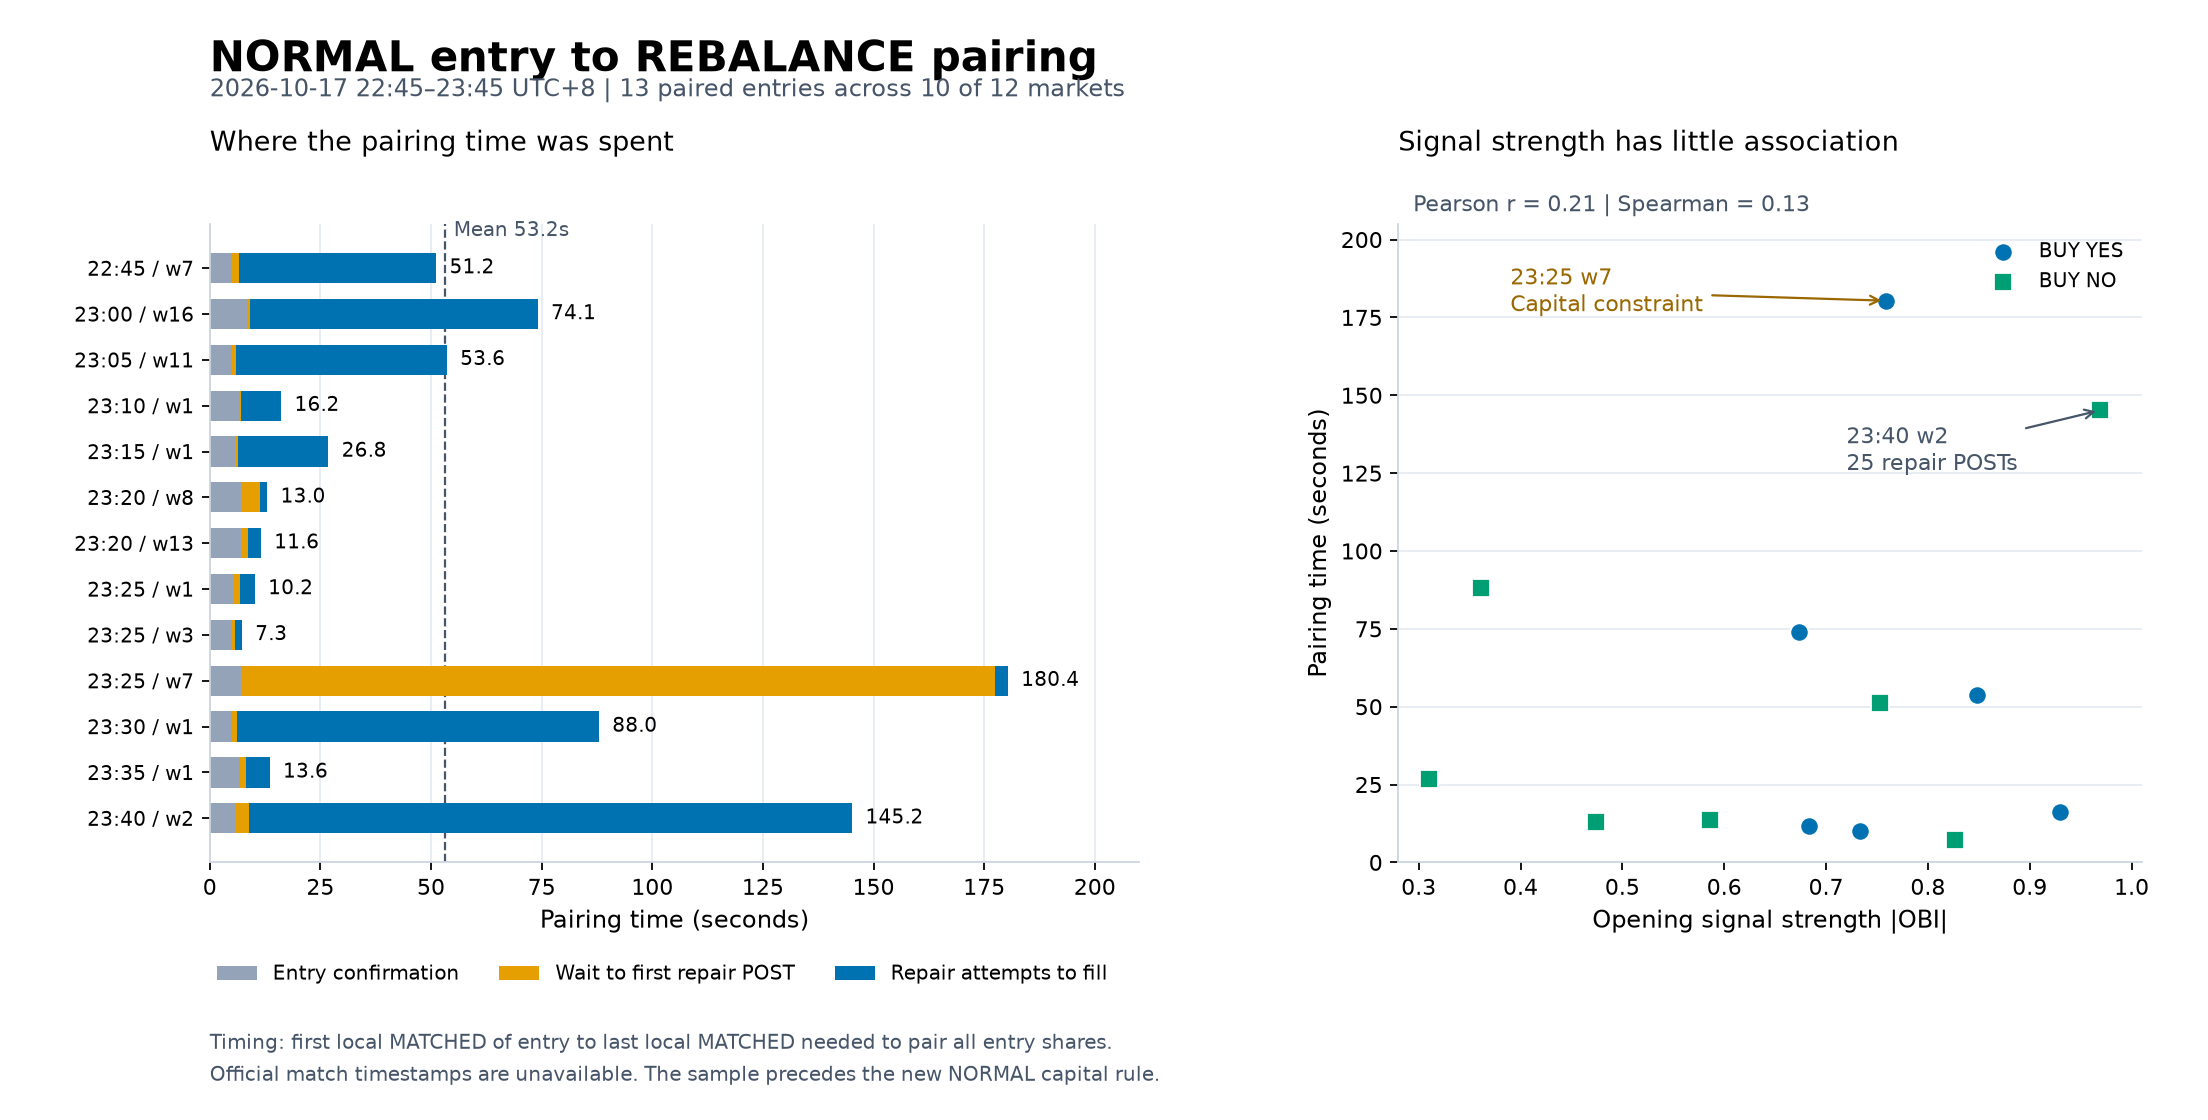

In [3]:
"""Static notebook companion charts from reviewed pairing evidence."""
import json
from pathlib import Path

import matplotlib

matplotlib.use('Agg')
import matplotlib.pyplot as plt

OUT=REVIEW


def build_plot(result):
    cycles=result['cycles']
    fig,(left,right)=plt.subplots(1,2,figsize=(13.8,7),gridspec_kw={'width_ratios':[1.25,1]})
    fig.subplots_adjust(left=.095,right=.97,top=.8,bottom=.23,wspace=.31)
    fig.suptitle('NORMAL entry to REBALANCE pairing',x=.095,y=.965,ha='left',fontsize=19,fontweight='bold')
    fig.text(.095,.914,'2026-10-17 22:45–23:45 UTC+8 | 13 paired entries across 10 of 12 markets',fontsize=11,color='#475569')
    stages=[('entry_confirmation_wait_s','Entry confirmation','#94a3b8'),
            ('confirmed_to_first_repair_post_s','Wait to first repair POST','#e69f00'),
            ('first_repair_post_to_pair_match_s','Repair attempts to fill','#0072b2')]
    position=list(range(len(cycles)))
    offset=[0.0]*len(cycles)
    for key,label,color in stages:
        vals=[c[key] for c in cycles]
        left.barh(position,vals,left=offset,color=color,label=label,height=.66)
        offset=[a+b for a,b in zip(offset,vals)]
    left.set_yticks(position,[c['market']+' / '+c['window'] for c in cycles],fontsize=9)
    left.invert_yaxis()
    left.set_xlim(0,210)
    left.set_xlabel('Pairing time (seconds)',fontsize=11)
    left.set_title('Where the pairing time was spent',loc='left',fontsize=12,pad=33)
    for y,c in enumerate(cycles):
        left.text(c['matched_to_matched_s']+3,y,f"{c['matched_to_matched_s']:.1f}",va='center',fontsize=9)
    mean=result['all']['metrics']['matched_to_matched_s']['mean']
    left.axvline(mean,color='#475569',lw=1,ls='--',zorder=0)
    left.text(mean+2,-.7,f'Mean {mean:.1f}s',fontsize=9,color='#475569')
    handles,legend_labels=left.get_legend_handles_labels()
    fig.legend(handles,legend_labels,loc='lower left',bbox_to_anchor=(.09,.105),
               fontsize=9,frameon=False,ncol=3)
    labels={'YES':('o','#0072b2'),'NO':('s','#009e73')}
    for side,(marker,color) in labels.items():
        group=[c for c in cycles if c['side']==side]
        right.scatter([c['signal_strength'] for c in group],[c['matched_to_matched_s'] for c in group],
                      marker=marker,s=68,c=color,label='BUY '+side,edgecolors='white',linewidths=.8,zorder=3)
    for c in cycles:
        if c['capital_constrained']:
            right.annotate('23:25 w7\nCapital constraint',xy=(c['signal_strength'],c['matched_to_matched_s']),
                           xytext=(.39,177),fontsize=10,color='#9a6700',
                           arrowprops={'arrowstyle':'->','color':'#9a6700','lw':1})
        elif c['market']=='23:40':
            right.annotate('23:40 w2\n25 repair POSTs',xy=(c['signal_strength'],c['matched_to_matched_s']),
                           xytext=(.72,126),fontsize=10,color='#475569',
                           arrowprops={'arrowstyle':'->','color':'#475569','lw':1})
    right.set_xlim(.28,1.01)
    right.set_ylim(0,205)
    right.set_xlabel('Opening signal strength |OBI|',fontsize=11)
    right.set_ylabel('Pairing time (seconds)',fontsize=11)
    right.set_title('Signal strength has little association',loc='left',fontsize=12,pad=33)
    corr=result['all']['signal_vs_duration']
    right.text(.02,1.02,f"Pearson r = {corr['pearson']:.2f} | Spearman = {corr['spearman']:.2f}",
               transform=right.transAxes,fontsize=10,color='#475569')
    right.legend(loc='upper right',frameon=False,fontsize=9)
    for ax in (left,right):
        ax.spines[['top','right']].set_visible(False)
        ax.spines[['left','bottom']].set_color('#cbd5e1')
        ax.set_axisbelow(True)
        ax.grid(axis='x' if ax==left else 'y',color='#e2e8f0',lw=.7)
    fig.text(.095,.035,'Timing: first local MATCHED of entry to last local MATCHED needed to pair all entry shares.\n'
             'Official match timestamps are unavailable. The sample precedes the new NORMAL capital rule.',
             fontsize=9,color='#475569',linespacing=1.6)
    fig.savefig(OUT/'pairing.png',dpi=160,facecolor='white')
    fig.savefig(OUT/'pairing.svg',facecolor='white')
    return fig


FIGURE=build_plot(RESULT)
plt.close(FIGURE)
from IPython.display import Image, display
display(Image(filename=str(OUT / 'pairing.png')))


## Takeaways

去掉已知资金受限的 23:25 w7，平均仍为 42.552 秒；开仓确认到首次补仓提交平均 1.512 秒，之后配对等待平均 34.958 秒。信号强度不足以解释这些执行路径。只有 13 轮、10 个有开仓市场；Pearson 分市场 bootstrap 近似 95% 区间为 −0.363 至 +0.693。该结果是描述性关联，不能证明信号有效或无效，也不能当成资金修复后的实盘结果。

来源与逐腿分配见 evidence.json，完整口径见 README.md。